# Recurrent Neural Networks

In [1]:
import torch
from torch import nn
from torch.nn import functional as F

import aif

## Recurrent Neural Networks with Hidden States

In [2]:
X, Wx = torch.randn(2, 3), torch.randn(3, 4)

H, Wh = torch.randn(2, 4), torch.randn(4, 4)

In [3]:
X @ Wx + H @ Wh

tensor([[ 1.3746,  0.8173,  1.1147, -0.0074],
        [-2.4938,  4.3224, -1.9816,  0.6466]])

In [4]:
XH = torch.cat((X, H), 1)
WxWh = torch.cat((Wx, Wh), 0)

XH @ WxWh

tensor([[ 1.3746,  0.8173,  1.1147, -0.0074],
        [-2.4938,  4.3224, -1.9816,  0.6466]])

## RNN from Scratch

In [5]:
class RNNScratch(aif.Module):
    def __init__(self, num_inputs, num_hiddens, lr=0.01, sigma=0.01):
        super().__init__(lr=lr)

        self.num_inputs = num_inputs
        self.num_hiddens = num_hiddens
        self.sigma = sigma

        self.W_xh = nn.Parameter(
            torch.randn(num_inputs, num_hiddens) * sigma
        )
        self.W_hh = nn.Parameter(
            torch.randn(num_hiddens, num_hiddens) * sigma
        )
        self.b_h = nn.Parameter(torch.zeros(num_hiddens))

    def forward(self, inputs, state=None):
        if state is None:
            state = torch.zeros(
                (inputs.shape[1], self.num_hiddens), 
                device=inputs.device
            )

        outputs = []
        for X in inputs:
            state = torch.tanh(
                X @ self.W_xh
                + state @ self.W_hh
                + self.b_h
            )
            outputs.append(state)

        return outputs, state

In [6]:
batch_size, num_inputs, num_hiddens, num_steps = 2, 16, 32, 100

rnn = RNNScratch(num_inputs, num_hiddens)
X = torch.ones((num_steps, batch_size, num_inputs))

outputs, state = rnn(X)

In [7]:
len(outputs), num_steps

(100, 100)

In [8]:
state.shape, (batch_size, num_hiddens)

(torch.Size([2, 32]), (2, 32))

In [9]:
outputs[0].shape, (batch_size, num_hiddens)

(torch.Size([2, 32]), (2, 32))

## Character-level RNN Language Model

In [10]:
class RNNLMScratch(aif.Classifier):
    def __init__(self, rnn, vocab_size, lr=0.01):
        super().__init__(lr=lr)
        
        self.rnn = rnn
        self.vocab_size = vocab_size
        self.lr = lr

        self.init_params()

    def init_params(self):
        self.W_hq = nn.Parameter(
            torch.randn(self.rnn.num_hiddens, self.vocab_size)
            * self.rnn.sigma
        )
        self.b_q = nn.Parameter(torch.zeros(self.vocab_size))

    def training_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1])
        
        return l

    def validation_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1])
        
        return {'loss': l}

    def one_hot(self, X):
        return F.one_hot(X.T, self.vocab_size).type(torch.float32)

    def output_layer(self, rnn_outputs):
        outputs = [(H @ self.W_hq + self.b_q) for H in rnn_outputs]

        return torch.stack(outputs, 1)

    def forward(self, X, state=None):
        embs = self.one_hot(X)
        rnn_outputs, _ = self.rnn(embs, state)

        return self.output_layer(rnn_outputs)

    def predict(self, prefix, num_preds, vocab, device=None):
        state, outputs = None, [vocab[prefix[0]]]
        
        for i in range(len(prefix) + num_preds - 1):
            X = torch.tensor([[outputs[-1]]], device=device)
            embs = self.one_hot(X)
            
            rnn_outputs, state = self.rnn(embs, state)
            
            if i < len(prefix) - 1:  # Warm-up period
                outputs.append(vocab[prefix[i + 1]])
            else:  # Predict num_preds steps
                Y = self.output_layer(rnn_outputs)
                outputs.append(int(Y.argmax(axis=2).reshape(1)))
        
        return ''.join([vocab.idx_to_token[i] for i in outputs])

In [11]:
model = RNNLMScratch(rnn, num_inputs)

outputs = model(torch.ones((batch_size, num_steps), dtype=torch.int64))

In [12]:
outputs.shape,  (batch_size, num_steps, num_inputs)

(torch.Size([2, 100, 16]), (2, 100, 16))

### Training

In [13]:
data = aif.TimeMachine(batch_size=1024, num_steps=32)

In [14]:
rnn = RNNScratch(num_inputs=len(data.vocab), num_hiddens=32)

model = RNNLMScratch(rnn, vocab_size=len(data.vocab), lr=1)

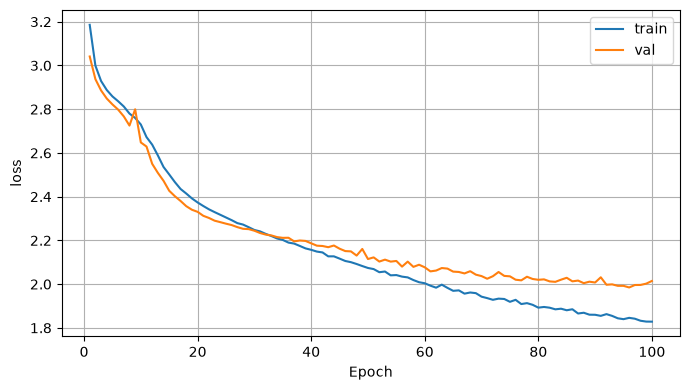

Epoch 100/100 | train_loss: 1.828459 | val_loss: 2.014496

In [15]:
trainer = aif.Trainer(max_epochs=100, gradient_clip_val=1, num_gpus=1)

trainer.fit(model, data)

### Prediction

In [16]:
model.predict('it has', 22, data.vocab, aif.device.try_gpu())

'it has of the the the the th'